# Training-image metadata

Distributions of the metadata the training query filters on, from `denormalized_metadata.csv` (the
Athena output of `sql/denormalized_training_metadata.sql`). This is where the cut-offs in
`sql/training_data_query.sql` came from: cloud cover < 5%, zero pixels < 10%, more than 50,000 pixels,
image quality 9. Writes `figures/distribution_of_metadata.jpg`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from glacierview import config

plt.style.use(config.mpl_style())
metadata_dir = config.processed_metadata_dir(config.TRAINING_DATA_LABEL)
df = pd.read_csv(metadata_dir / "denormalized_metadata.csv")
df["image_quality"].value_counts().sort_index()

image_quality
5.0       109
7.0     16293
9.0    255863
Name: count, dtype: int64

In [2]:
columns = ["cloud_cover", "percentage_zero_pixels", "num_pixels", "no_data_pixel_count",
           "negative_pixel_count"]
df[columns].describe(percentiles=[0.5, 0.95, 0.99, 0.999]).T

,count,mean,std,min,50%,95%,99%,99.9%,max
cloud_cover,272265.0,33.974380,30.963336,0.0,24.00000,9.000000e+01,9.700000e+01,1.000000e+02,1.000000e+02
percentage_zero_pixels,272265.0,0.128483,0.091003,0.0,0.10512,2.867561e-01,4.723596e-01,5.276688e-01,8.947368e-01
num_pixels,272265.0,304028.270722,507281.243406,19.0,131670.00000,1.187424e+06,2.648657e+06,4.520100e+06,9.896150e+06
no_data_pixel_count,272265.0,1160.384232,24989.280992,0.0,0.00000,0.000000e+00,0.000000e+00,4.183625e+05,1.474491e+06
negative_pixel_count,272265.0,23934.347544,85164.089609,0.0,4754.00000,9.398360e+04,3.590579e+05,1.127754e+06,4.637315e+06


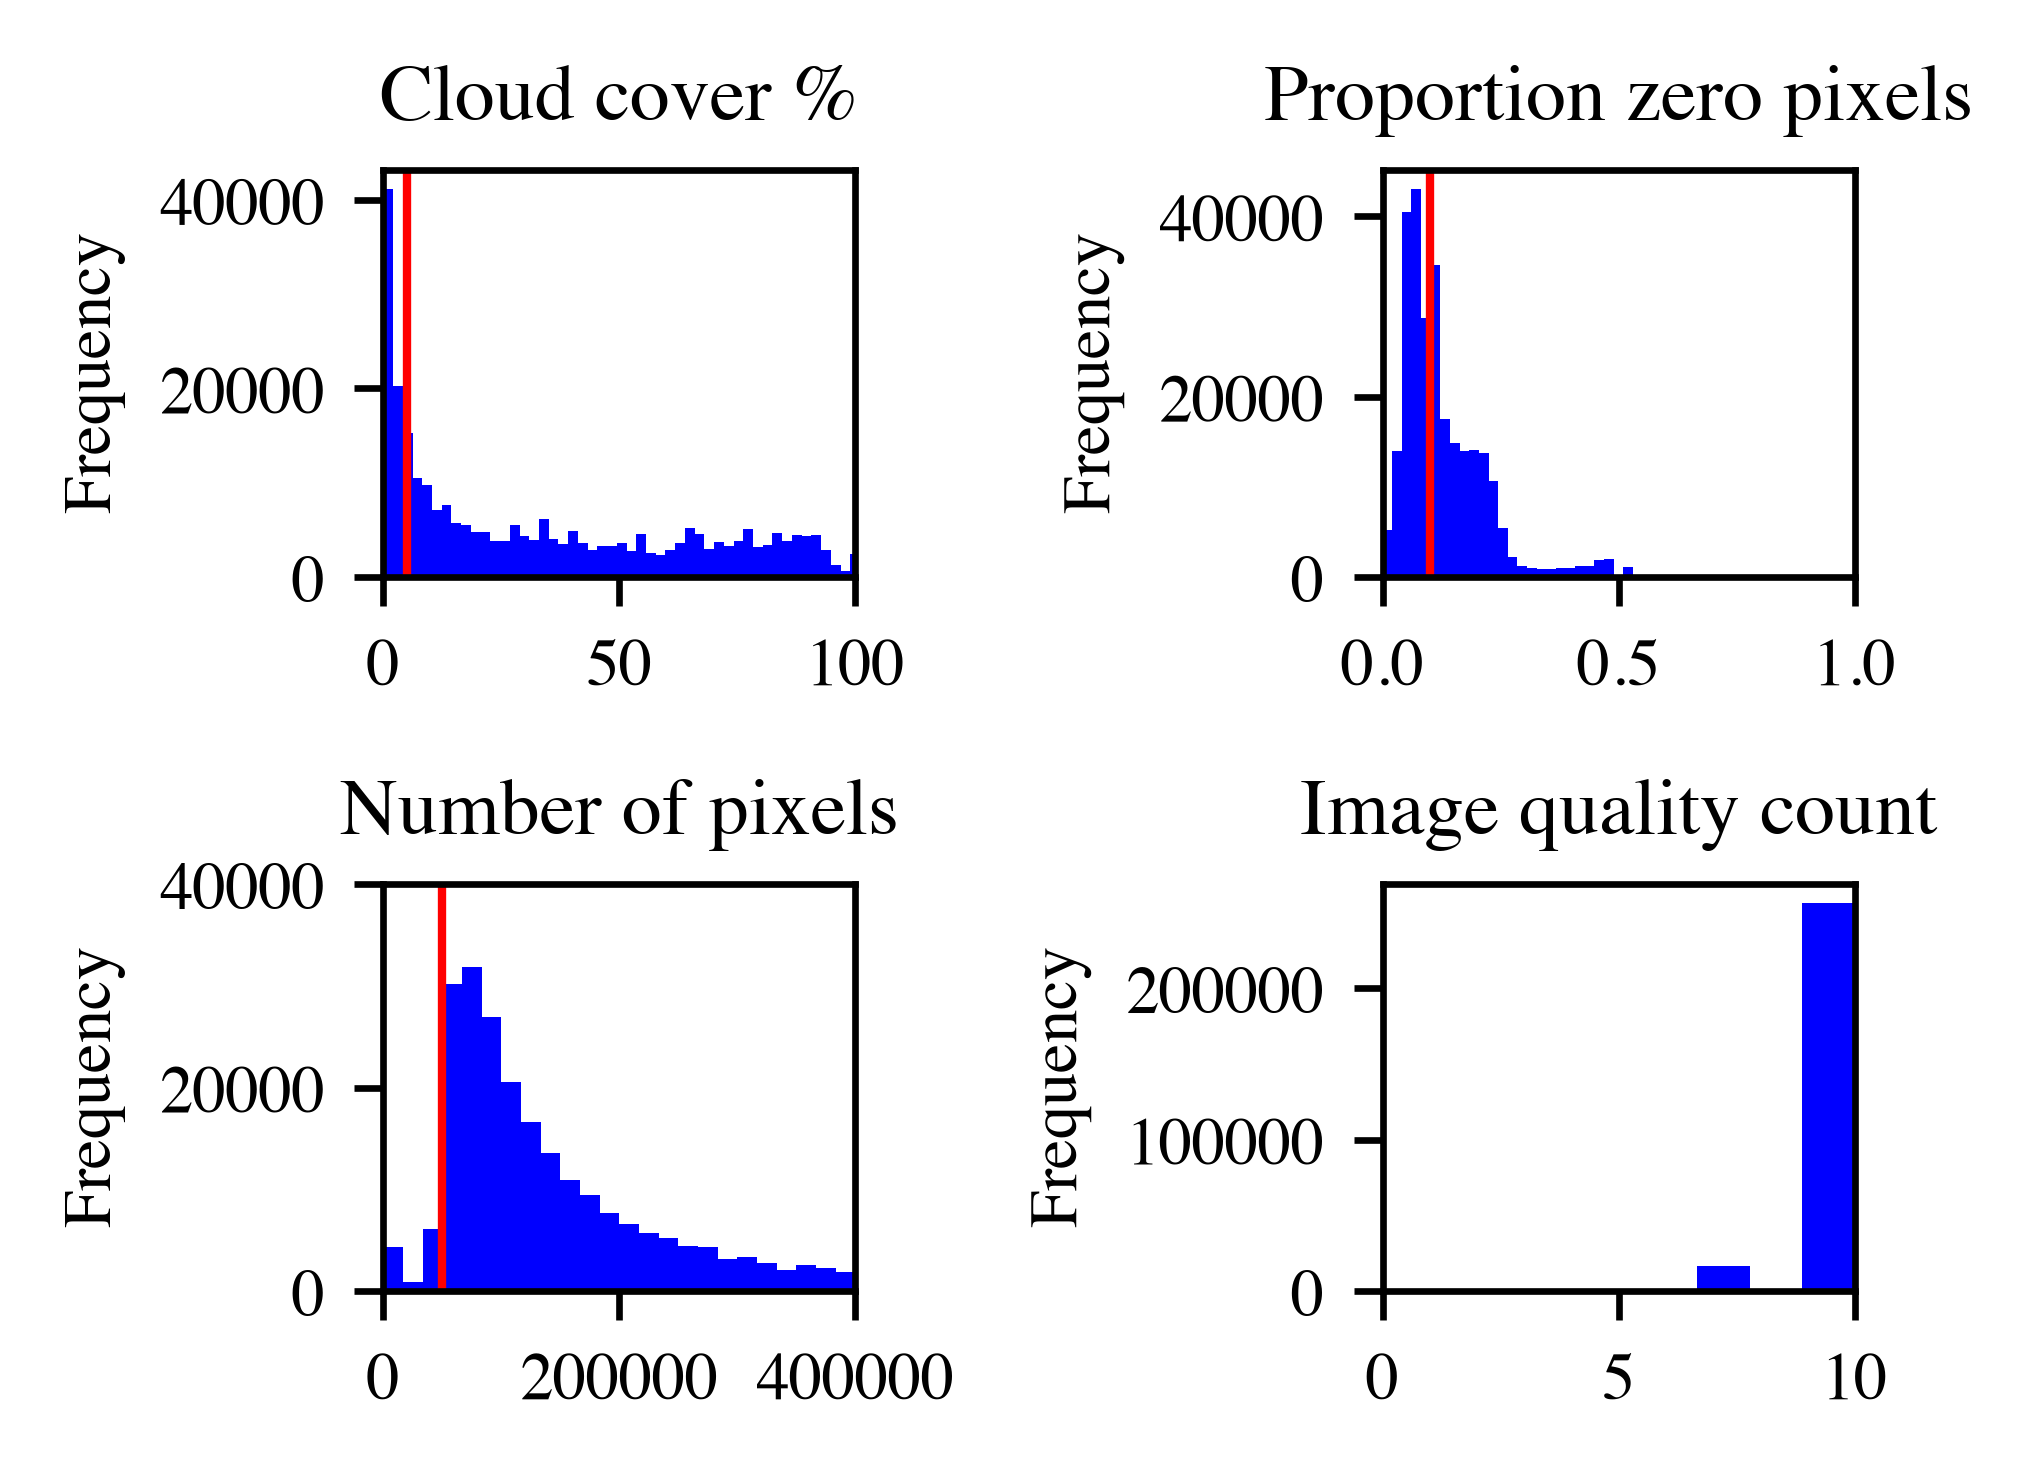

In [3]:
panels = [
    ("cloud_cover", "Cloud cover %", np.linspace(0, 101, 50), (0, 100), 5),
    ("percentage_zero_pixels", "Proportion zero pixels", np.linspace(0, 1, 50), (0, 1), 0.1),
    ("num_pixels", "Number of pixels", np.linspace(0, 400_000, 25), (0, 400_000), 50_000),
    ("image_quality", "Image quality count", np.linspace(0, 10, 10), (0, 10), None),
]
fig, axs = plt.subplots(2, 2)
for ax, (column, title, bins, xlim, cutoff) in zip(axs.flat, panels, strict=True):
    ax.hist(df[column], bins=bins)
    ax.set(title=title, xlim=xlim, ylabel="Frequency")
    if cutoff is not None:
        ax.axvline(cutoff, color="red")
axs[1, 0].set_yticks([0, 20_000, 40_000])
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "distribution_of_metadata.jpg", dpi=600)